# Mixed-Precision Optimization on GPU Hardware

This tutorial demonstrates the full mixed-precision optimization pipeline:

1. **Hardware definition** -- a cluster of 5 NVIDIA A100-80GB GPUs
2. **Hamiltonian construction** -- DMDS molecule with a small active space
3. **Accuracy vs cost sweep** -- product formulas at different precisions and step counts
4. **Constraint-driven optimization** -- using hardware-aware spacetime cost
5. **OpenEvolve optimization** -- 100 epochs to find the best precision schedule
6. **Results overlay** -- optimized point on the tradeoff plot

The key metric is **emulated spacetime cost** (byte-seconds): for each term in the
Trotter product, FLOPs are divided by the GPU throughput *at that term's precision*,
then multiplied by peak memory.  This gives a physically meaningful resource measure
for mixed-precision workloads on real hardware.

For the constraint system and evaluator tutorials, see
[Evaluations](evaluations.ipynb) and [Filemaker](filemaker.ipynb).

## 1. Setup and Hardware

In [1]:
import numpy as np
import scipy
import matplotlib.pyplot as plt
import pickle
import os
from pathlib import Path
from tqdm.notebook import tqdm

import trovolut as trv
trv.set_backend('gpu-mp-emulator')

In [2]:
gpu = trv.hardware.gpus.A100 
cluster = 5 * gpu # 5x A100-80GB

print(f"Cluster: 5x {gpu.name}")
print(f"  Total VRAM:       {cluster.total_memory_bytes / 1e9:.0f} GB")
print(f"  FP64 throughput:  {cluster.total_spec('fp64_flops') / 1e12:.1f} TFLOPS")
print(f"  FP32 throughput:  {cluster.total_spec('fp32_flops') / 1e12:.1f} TFLOPS")
print(f"  FP16 throughput:  {cluster.total_spec('fp16_flops') / 1e12:.0f} TFLOPS")
print(f"  BF16 throughput:  {cluster.total_spec('bf16_flops') / 1e12:.0f} TFLOPS")

Cluster: 5x A100-80GB
  Total VRAM:       429 GB
  FP64 throughput:  48.5 TFLOPS
  FP32 throughput:  97.5 TFLOPS
  FP16 throughput:  1560 TFLOPS
  BF16 throughput:  1560 TFLOPS


## 2. DMDS Hamiltonian (small active space)

In [3]:
from rdkit import Chem
from rdkit.Chem import AllChem

def get_hamiltonian():
    """Build a qubit Hamiltonian for DMDS (dimethyl disulfide) with a minimal active space."""
    mol = Chem.AddHs(Chem.MolFromSmiles('CSSC'))
    AllChem.EmbedMolecule(mol, AllChem.ETKDGv3())
    AllChem.UFFOptimizeMolecule(mol)

    conf = mol.GetConformer()
    atoms = [a.GetSymbol() for a in mol.GetAtoms()]
    xyz = (
        f"{len(atoms)}\ndmds\n"
        + "\n".join(
            f"{s} {conf.GetAtomPosition(i).x:.8f} "
            f"{conf.GetAtomPosition(i).y:.8f} "
            f"{conf.GetAtomPosition(i).z:.8f}"
            for i, s in enumerate(atoms)
        )
    )

    H = trv.qm.ElectronicHamiltonian.from_xyz(
        xyz_source=xyz,
        basis='sto-3g',
        charge=0,
        spin_mult=1,
        use_gpu4pyscf=False,
        freeze_core=True,
        n_core_keep=1,
        n_virt_keep=1,
    ).to_qubits()

    return [t['coef'] * t['matrix'] for t in H.terms()]

hams = get_hamiltonian()
hams_no_id = hams[1:]  # drop identity term
dim = hams[0].shape[0]
n_qubits = int(np.log2(dim))

print(f"DMDS Hamiltonian: {len(hams_no_id)} Pauli terms, {n_qubits} qubits, dim={dim}")

converged SCF energy = -864.654938672562
DMDS Hamiltonian: 30 Pauli terms, 8 qubits, dim=256


## 3. Accuracy vs Spacetime Cost Sweep

We sweep over:
- **Product formulas**: 1st order (Lie-Trotter), 2nd order (Suzuki-Trotter), 4th order (Suzuki high-order)
- **Precisions**: FP16-only, FP64-only, Mixed (cycle FP32/FP16/BF16)
- **Step counts**: 2, 4, 8, 16, 32, 64

For each configuration, we compute the **emulated spacetime cost** on the 5x A100
cluster and measure infidelity against exact evolution.

In [4]:
# ── Accuracy metrics ────────────────────────────────────────

def infidelity(psi_approx, psi_exact):
    """1 - |<exact|approx>|^2"""
    overlap = np.abs(np.vdot(psi_exact, psi_approx)) ** 2
    return max(0.0, 1.0 - overlap)

def exact_evolution(hams, t, psi0):
    """Exact evolution via matrix exponential."""
    H_full = sum(hams)
    return scipy.linalg.expm(-1j * H_full * t) @ psi0

# ── Sweep configuration ─────────────────────────────────────

formulas = {
    'First Order': trv.dynamics.LieTrotter(),
    'Second Order': trv.dynamics.SuzukiTrotter(),
    # 'Fourth Order': trv.dynamics.SuzukiHighOrder(4),
}

precision_configs = {
    'FP16': lambda n_terms: [trv.dynamics.Precision.FP16] * n_terms,
    'FP64': lambda n_terms: [trv.dynamics.Precision.FP64] * n_terms,
    'Mixed': lambda n_terms: [
        [trv.dynamics.Precision.FP32, trv.dynamics.Precision.FP16, trv.dynamics.Precision.BF16][i % 3]
        for i in range(n_terms)
    ],
}

step_counts = [2, 4, 8, 16, 32, 64]
n_trials = 5
total_time = 1.0

print(f"Sweep: {len(formulas)} formulas x {len(precision_configs)} precisions "
      f"x {len(step_counts)} step counts = {len(formulas)*len(precision_configs)*len(step_counts)} configs")
print(f"Trials per config: {n_trials}")

Sweep: 2 formulas x 3 precisions x 6 step counts = 36 configs
Trials per config: 5


In [ ]:
# ── Run sweep ───────────────────────────────────────────────

all_results = []

total_configs = len(formulas) * len(precision_configs) * len(step_counts)
pbar = tqdm(total=total_configs, desc="Sweep", unit="cfg")

for formula_name, formula in formulas.items():
    for prec_name, prec_fn in precision_configs.items():
        precisions = prec_fn(len(hams_no_id))
        for n_steps in step_counts:
            pbar.set_postfix_str(f"{formula_name} | {prec_name} | n={n_steps}")

            # Build high-level evolution object
            evo = trv.dynamics.MPTrotterEvolution(
                trotter_steps=n_steps,
                formula=formula,
                precision_schedule=precisions,
            )

            # Cost analysis (static, uses CostAnalyzer internally)
            cost = evo.cost_profile(hams_no_id)
            emulated_st = cost.emulated_spacetime(cluster)

            # Run trials for accuracy
            infidelities = []
            for _ in range(n_trials):
                psi0 = np.random.randn(dim) + 1j * np.random.randn(dim)
                psi0 /= np.linalg.norm(psi0)
                psi_exact = exact_evolution(hams_no_id, total_time, psi0)
                psi_approx = evo.evolve(hams_no_id, psi0, total_time)
                infidelities.append(infidelity(psi_approx, psi_exact))

            all_results.append({
                'formula': formula_name,
                'precision': prec_name,
                'n_steps': n_steps,
                'emulated_spacetime': emulated_st,
                'emulated_time_s': cost.emulated_time(cluster),
                'peak_memory_bytes': cost.peak_memory_bytes,
                'total_flops': cost.total_flops,
                'total_depth': cost.total_depth,
                'space_time_product': cost.space_time_product,
                'infidelity_mean': float(np.mean(infidelities)),
                'infidelity_std': float(np.std(infidelities)),
            })

            pbar.update(1)

pbar.close()

# Save results
Path('data').mkdir(exist_ok=True)
with open('data/tradeoff_results.pkl', 'wb') as f:
    pickle.dump(all_results, f)

print(f"\nDone: {len(all_results)} configurations saved to data/tradeoff_results.pkl")

## 4. Baseline Tradeoff Plot

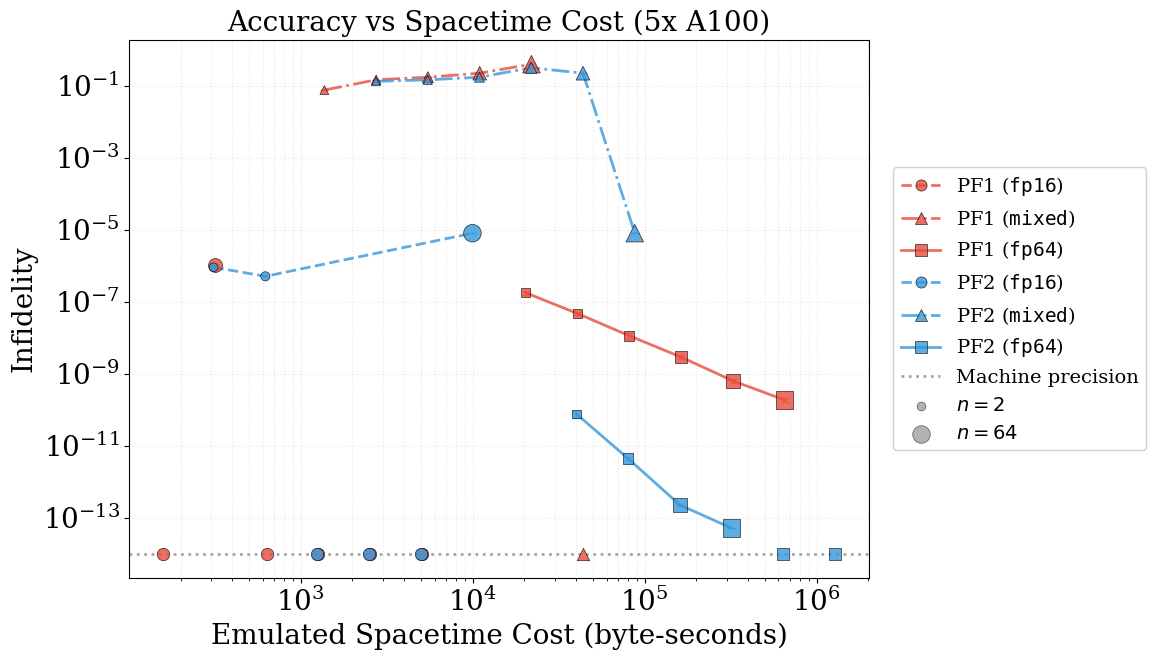

Saved to data/baseline_tradeoff.pdf


In [5]:
# ── Plot configuration ──────────────────────────────────────

COST_METRIC = 'emulated_spacetime'   # x-axis: byte-seconds on cluster
ERROR_METRIC = 'infidelity'
ERROR_METRIC_MEAN = ERROR_METRIC + '_mean'
ERROR_METRIC_STD = ERROR_METRIC + '_std'
MIN_ERROR = 1e-14

plt.rcParams.update({
    'text.usetex': False, 'font.family': 'serif', 'font.size': 20,
    'xtick.labelsize': 20, 'ytick.labelsize': 20,
    'axes.labelsize': 20, 'axes.titlesize': 20, 'legend.fontsize': 14,
})

with open('data/tradeoff_results.pkl', 'rb') as f:
    all_results = pickle.load(f)

# ── Build plot ───────────────────────────────────────────────

formula_colors = {'First Order': '#E74C3C', 'Second Order': '#3498DB', 'Fourth Order': '#2ECC71'}
formula_labels = {'First Order': 'PF1', 'Second Order': 'PF2', 'Fourth Order': 'PF4'}
precision_markers = {'FP16': 'o', 'FP64': 's', 'Mixed': '^'}
precision_linestyles = {'FP16': '--', 'FP64': '-', 'Mixed': '-.'}
precision_labels = {'FP16': 'fp16', 'FP64': 'fp64', 'Mixed': 'mixed'}


def plot_tradeoff(results, ax, extra_points=None):
    """Plot accuracy vs spacetime cost tradeoff."""
    for formula_name in ['First Order', 'Second Order', 'Fourth Order']:
        for prec_name in ['FP16', 'Mixed', 'FP64']:
            config_results = sorted(
                [r for r in results if r['formula'] == formula_name and r['precision'] == prec_name],
                key=lambda x: x[COST_METRIC],
            )
            if not config_results:
                continue

            costs, errors, stds, costs_zero = [], [], [], []
            for r in config_results:
                if r[ERROR_METRIC_MEAN] > MIN_ERROR:
                    costs.append(r[COST_METRIC])
                    errors.append(r[ERROR_METRIC_MEAN])
                    stds.append(r[ERROR_METRIC_STD])
                else:
                    costs_zero.append(r[COST_METRIC])

            label = f"{formula_labels[formula_name]} ($\\mathtt{{{precision_labels[prec_name]}}}$)"

            if costs:
                costs_a, errors_a, stds_a = np.array(costs), np.array(errors), np.array(stds)
                n_steps_vals = np.array([r['n_steps'] for r in config_results if r[ERROR_METRIC_MEAN] > MIN_ERROR])
                if len(n_steps_vals) > 1:
                    sizes = 40 + (n_steps_vals - n_steps_vals.min()) / (n_steps_vals.max() - n_steps_vals.min()) * 120
                else:
                    sizes = np.array([100])

                ax.plot(costs_a, errors_a, color=formula_colors[formula_name],
                        linestyle=precision_linestyles[prec_name], linewidth=2, alpha=0.8)
                ax.errorbar(costs_a, errors_a, yerr=stds_a, fmt='none',
                            ecolor=formula_colors[formula_name], elinewidth=1, capsize=3, alpha=0.5)
                ax.scatter(costs_a, errors_a, marker=precision_markers[prec_name], s=sizes,
                           color=formula_colors[formula_name], edgecolors='black', linewidths=0.5, alpha=0.8, zorder=5)
                ax.plot([], [], marker=precision_markers[prec_name], color=formula_colors[formula_name],
                        linestyle=precision_linestyles[prec_name], linewidth=2, markersize=8, label=label,
                        markeredgecolor='black', markeredgewidth=0.5, alpha=0.8)

            if costs_zero:
                ax.scatter(costs_zero, [MIN_ERROR] * len(costs_zero),
                           marker=precision_markers[prec_name], color=formula_colors[formula_name],
                           s=80, edgecolors='black', linewidths=0.5, alpha=0.8, zorder=10,
                           label=label if not costs else None)

    ax.axhline(y=MIN_ERROR, color='gray', linestyle=':', linewidth=2, alpha=0.7, label='Machine precision')

    # Extra points (e.g., OpenEvolve optimized)
    if extra_points:
        for ep in extra_points:
            ax.scatter(ep['cost'], ep['error'], marker='*', s=400, color='gold',
                       edgecolors='black', linewidths=1.5, zorder=20, label=ep.get('label', 'Optimized'))

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel('Emulated Spacetime Cost (byte-seconds)')
    ax.set_ylabel('Infidelity')
    ax.grid(True, which='both', alpha=0.3, linestyle=':')
    ax.set_title('Accuracy vs Spacetime Cost (5x A100)')

    # Size reference
    for n_ref in [step_counts[0], step_counts[-1]]:
        sz = 40 + (n_ref - step_counts[0]) / max(step_counts[-1] - step_counts[0], 1) * 120
        ax.scatter([], [], s=sz, color='gray', edgecolors='black', linewidths=0.5,
                   label=f'$n={n_ref}$', alpha=0.6)

    ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=True, framealpha=0.9, ncol=1)


fig, ax = plt.subplots(1, 1, figsize=(12, 7))
plot_tradeoff(all_results, ax)
plt.tight_layout()
plt.savefig('data/baseline_tradeoff.pdf', bbox_inches='tight')
plt.show()
print("Saved to data/baseline_tradeoff.pdf")

## 5. Define Constraints from Cluster

We use the **hardware-aware** `SpaceTimeCost` constraint, which computes
emulated spacetime in byte-seconds by dividing FLOPs at each precision by
the cluster's throughput at that precision.

In [6]:
# Pick a spacetime budget from the sweep: the median cost of 2nd-order FP32 at 32 steps
ref = [r for r in all_results if r['formula'] == 'Second Order' and r['precision'] == 'Mixed' and r['n_steps'] == 32]
if ref:
    st_budget = ref[0]['emulated_spacetime'] * 2  # allow 2x the reference
else:
    st_budget = 1e6  # fallback

spacetime_constr = trv.constraints.SpaceTimeCost(
    max_product=st_budget,
    hardware=cluster,
    weight=1.0,
    hard=False,
    score_fn='exponential',
)
error_constr = trv.constraints.Error(max_error=10e-8, hard=False, weight=2, score_fn='exponential')
group = trv.constraints.Group([spacetime_constr, error_constr])

print(f"Spacetime budget: {st_budget:.2e} byte-seconds")
print(f"Memory budget:    {cluster.total_memory_bytes / 1e9:.0f} GB (cluster total)")
print(f"Error budget:     0.01 (hard)")
print(f"\n{group.formula()}")

Spacetime budget: 8.76e+04 byte-seconds
Memory budget:    429 GB (cluster total)
Error budget:     0.01 (hard)

Soft score: (1.0·s_space_time_cost + 2·s_error) / 3.0


## 6. Initial Program and Evaluator

In [7]:
Path('opt').mkdir(exist_ok=True)

# ── Initial program ─────────────────────────────────────────

def run_dynamics(hams, t, psi0):
    """Mixed-precision Trotter evolution (baseline: FP32, 2nd order, 50 steps)."""
    import numpy as np

    trv.filemaker.EVO_START
    formula = trv.dynamics.SuzukiTrotter()
    precision_schedule = trv.dynamics.PrecisionConfig(
        compute=trv.dynamics.Precision.FP32,
        storage=trv.dynamics.Precision.FP32,
        accumulate=trv.dynamics.Precision.FP64,
    )
    n_steps = 50
    trv.filemaker.EVO_END
    evolution = trv.dynamics.MPTrotterEvolution(
        trotter_steps=n_steps,
        formula=formula,
        precision_schedule=precision_schedule,
    )
    return evolution.evolve(hams, psi0, t)


# ── Test generator and exact fn ─────────────────────────────

# Cache the Hamiltonian — the molecule / basis / active space are fixed,
# so there is no need to redo the SCF on every trial.
_cached_hams = None

def get_test_cases():
    """Generate a random test case (random psi0, cached Hamiltonian)."""
    global _cached_hams
    if _cached_hams is None:
        _cached_hams = get_hamiltonian()[1:]  # drop identity
    dim = _cached_hams[0].shape[0]
    psi0 = np.random.randn(dim) + 1j * np.random.randn(dim)
    psi0 /= np.linalg.norm(psi0)
    t = 1.0
    return _cached_hams, psi0, t

def exact_fn(hams, t, psi0):
    """Exact evolution via matrix exponential."""
    import scipy.linalg
    import numpy as np
    return scipy.linalg.expm(-1j * sum(hams) * t) @ psi0


# ── Build workflow + evaluator ──────────────────────────────

workflow = trv.filemaker.Workflow(
    [run_dynamics],
    out_path='opt/initial_program.py',
    include_api_reference=True, 
)

evaluator = trv.filemaker.Evaluator(
    test_generator=get_test_cases,
    workflow=workflow,
    constraints=group,
    exact_fn=exact_fn,
    out_path='opt/evaluator.py',
    n_trials=5,
    timeout=60,
)

init_path = workflow.build()
eval_path = evaluator.build()

print(f"Initial program: {init_path}")
print(f"Evaluator:       {eval_path}")
print(f"Runner:          {evaluator.runner}")

Initial program: opt/initial_program.py
Evaluator:       opt/evaluator.py
Runner:          CPURunner()


## 7. Test Evaluator

In [8]:
exec(open(eval_path).read())
result = evaluate(str(init_path))

print(f"combined_score: {result['combined_score']:.6f}")
print(f"std_score:      {result.get('std_score', 0):.6f}")
print(f"all_satisfied:  {result.get('all_satisfied', 'N/A')}")
print(f"time:           {result.get('time', 0):.4f}s")
print(f"error:          {result.get('error', 0):.6e}")

if 'details' in result:
    print(f"\nConstraint details:")
    for name, info in result['details'].items():
        print(f"  {name}: value={info.get('value', '?'):.4e}, "
              f"score={info.get('score', '?'):.4f}, satisfied={info.get('satisfied', '?')}")

converged SCF energy = -864.654938666712
converged SCF energy = -864.654938704692
converged SCF energy = -864.654938691007
converged SCF energy = -864.654938694556
converged SCF energy = -864.654938665447
converged SCF energy = -864.654938657898
combined_score: 0.042350
std_score:      0.000000
all_satisfied:  True
time:           8.2612s
error:          2.804111e-06

Constraint details:
  space_time_cost: value=2.4916e+05, score=0.0582, satisfied=False
  error: value=2.8041e-06, score=0.0689, satisfied=False


## 8. OpenEvolve Optimization (100 epochs)

We let OpenEvolve search for the best precision schedule, formula order, step count,
and decomposition strategy -- all constrained to the spacetime budget of our 5x A100 cluster.

In [9]:
# Print the LLM instructions auto-generated from constraints
print(group.generate_llm_instructions())

You are optimizing quantum simulation code. Your objectives are:

**Optimization goals (weighted):**
- Minimize spacetime cost (byte-seconds) (target: <8.76e+04, weight: 1.0).
- Minimize error (weight: 2).


In [10]:
import nest_asyncio
nest_asyncio.apply()

from openevolve import run_evolution
from openevolve.config import Config, LLMModelConfig, PromptConfig

config = Config(checkpoint_interval=10, max_code_length=50000)
config.prompt = PromptConfig(system_message=group.generate_llm_instructions())

# Configure LLM endpoint (adjust API key as needed)
config.llm.models = [
    LLMModelConfig(
        name='openai/openai/gpt-5.2',
        api_base='https://inference-api.nvidia.com/v1',
        api_key=os.getenv('NVIDIA_API_KEY'),
        temperature=0.7,
        # max_tokens=1024,
    )
]

result_evo = run_evolution(
    initial_program=str(init_path),
    evaluator=str(eval_path),
    iterations=100,
    config=config,
    output_dir='opt/evolution_results',
)

2026-02-06 18:21:10,334 - INFO - Logging to opt/evolution_results/logs/openevolve_20260206_182110.log
/Users/lmantilla/Desktop/Internship/trovolut/.venv/lib/python3.12/site-packages/openevolve/controller.py:96: Warning: 
        Seeding the random number generator with a non-constant value
        inside Legate can lead to undefined behavior and/or errors when
        the program is executed with multiple ranks.
  random.seed(self.config.random_seed)
/Users/lmantilla/Desktop/Internship/trovolut/.venv/lib/python3.12/site-packages/openevolve/controller.py:97: Warning: 
        Seeding the random number generator with a non-constant value
        inside Legate can lead to undefined behavior and/or errors when
        the program is executed with multiple ranks.
  np.random.seed(self.config.random_seed)
2026-02-06 18:21:10,335 - INFO - Set random seed to 42 for reproducibility
2026-02-06 18:21:10,368 - INFO - Initialized OpenAI LLM with model: openai/openai/gpt-5.2
2026-02-06 18:21:10,368 

converged SCF energy = -864.654938665793
converged SCF energy = -864.654938672794
converged SCF energy = -864.654938697059
converged SCF energy = -864.654938674355
converged SCF energy = -864.65493866654
converged SCF energy = -864.654938649356


2026-02-06 18:21:52,599 - INFO - Evaluated program 961b5dd0-be96-47a2-ac4f-9778c1f47d04 in 42.22s: combined_score=0.0423, std_score=0.0000, all_satisfied=1.0000, details={'space_time_cost': {'value': 249159.41371062954, 'score': 0.05818065675259499, 'satisfied': False}, 'error': {'value': 2.8040916896754357e-06, 'score': 0.06886834899567244, 'satisfied': False}}, time=8.2143, error=0.0000, memory_peak_bytes=0.0000, gpu_seconds=None, makespan_seconds=None, peak_fb_mb=None
2026-02-06 18:21:52,600 - INFO - New MAP-Elites cell occupied in island 0: {'complexity': 5, 'diversity': 0}
2026-02-06 18:21:52,625 - INFO - Initialized process parallel controller with 1 workers
2026-02-06 18:21:52,627 - INFO - Set max None tasks per child
2026-02-06 18:21:52,628 - INFO - Started process pool with 1 processes
2026-02-06 18:21:52,628 - INFO - Using island-based evolution with 5 islands
2026-02-06 18:21:52,629 - INFO - Island Status:
2026-02-06 18:21:52,629 - INFO -  * Island 0: 1 programs, best=0.0423

converged SCF energy = -864.654938672562
converged SCF energy = -864.654938666712
converged SCF energy = -864.654938704692
converged SCF energy = -864.654938691007
converged SCF energy = -864.654938694556


2026-02-06 18:23:03,080 - INFO - New MAP-Elites cell occupied in island 0: {'complexity': 9, 'diversity': 5}
2026-02-06 18:23:03,081 - INFO - Iteration 1: Program d40d7bf5-6125-4c59-be6f-1c3e3d15b34b (parent: 961b5dd0-be96-47a2-ac4f-9778c1f47d04) completed in 67.48s
2026-02-06 18:23:03,081 - INFO - Metrics: combined_score=0.0164, std_score=0.0000, all_satisfied=1.0000, details={'space_time_cost': {'value': 298991.29645275546, 'score': 0.03294081524226914, 'satisfied': False}, 'error': {'value': 1.2155670718505773e-05, 'score': 0.016318976300334565, 'satisfied': False}}, time=9.7477, error=0.0000, memory_peak_bytes=0.0000, gpu_seconds=None, makespan_seconds=None, peak_fb_mb=None


converged SCF energy = -864.654938665447
converged SCF energy = -864.654938657898
converged SCF energy = -864.654938665793
converged SCF energy = -864.654938672794
converged SCF energy = -864.654938697059
converged SCF energy = -864.654938674355


... (215 outputs left out)

converged SCF energy = -864.654938673859
converged SCF energy = -864.654938700393
converged SCF energy = -864.654938736219
converged SCF energy = -864.654938709554
converged SCF energy = -864.654938694075


2026-02-09 03:45:54,223 - INFO - New MAP-Elites cell occupied in island 4: {'complexity': 2, 'diversity': 4}
2026-02-09 03:45:54,223 - INFO - Iteration 100: Program e2156b71-7388-49df-980b-7c31b8db8c02 (parent: 3a8e33b4-6fa5-4c19-aab1-e1aac768875f) completed in 15331.39s
2026-02-09 03:45:54,224 - INFO - Metrics: combined_score=0.2651, std_score=0.0000, all_satisfied=1.0000, details={'space_time_cost': {'value': 20270.596369678336, 'score': 0.7934277999091669, 'satisfied': True}, 'error': {'value': 0.00010243063851823463, 'score': 0.0019506364428270957, 'satisfied': False}}, time=0.7971, error=0.0001, memory_peak_bytes=0.0000, gpu_seconds=None, makespan_seconds=None, peak_fb_mb=None
2026-02-09 03:45:54,224 - INFO - Checkpoint interval reached at iteration 100
2026-02-09 03:45:54,227 - INFO - Island Status:
2026-02-09 03:45:54,228 - INFO -  * Island 0: 52 programs, best=0.3820, avg=0.2311, diversity=23.17, gen=78 (best: 0eb4010a-446c-40a1-9114-df81a9833897)
2026-02-09 03:45:54,228 - INFO

converged SCF energy = -864.654938649746


2026-02-09 03:45:54,401 - INFO - Saved database with 103 programs to opt/evolution_results/checkpoints/checkpoint_100
2026-02-09 03:45:54,409 - INFO - Saved best program at checkpoint 100 with metrics: combined_score=0.3820, std_score=0.0000, all_satisfied=1.0000, details={'space_time_cost': {'value': 400666.5145542855, 'score': 0.010319862357720647, 'satisfied': False}, 'error': {'value': 7.611361707405259e-08, 'score': 1.1356305283077779, 'satisfied': True}}, time=3.3264, error=0.0000, memory_peak_bytes=0.0000, gpu_seconds=None, makespan_seconds=None, peak_fb_mb=None
2026-02-09 03:45:54,409 - INFO - Saved checkpoint at iteration 100 to opt/evolution_results/checkpoints/checkpoint_100
2026-02-09 03:45:54,410 - INFO - ✅ Evolution completed - Maximum iterations reached
2026-02-09 03:45:54,507 - INFO - Saved database with 103 programs to opt/evolution_results/checkpoints/checkpoint_100
2026-02-09 03:45:54,508 - INFO - Saved best program at checkpoint 100 with metrics: combined_score=0.38

## 9. Overlay Optimized Result on Tradeoff Plot

In [ ]:
# ── Evaluate the optimized program ──────────────────────────
import importlib.util

best_path = 'opt/evolution_results/best/best_program.py'
spec = importlib.util.spec_from_file_location('best', best_path)
best_mod = importlib.util.module_from_spec(spec)
spec.loader.exec_module(best_mod)

# Run optimized program and measure cost + accuracy
opt_infidelities = []

for _ in range(n_trials):
    h, psi0, t = get_test_cases()
    psi_exact = exact_fn(h, t, psi0)
    psi_opt = best_mod.run_dynamics(h, t, psi0)
    if isinstance(psi_opt, tuple):
        psi_opt = psi_opt[0]
    opt_infidelities.append(infidelity(psi_opt, psi_exact))

# Get spacetime cost from the evaluator — the constraint system already
# computes it properly via TrotterSimulator.cost_profile().
opt_result = evaluate(best_path)
opt_spacetime = opt_result.get('details', {}).get('space_time_cost', {}).get('value', None)

# Fallback: recompute directly from cost profile data in the result
if opt_spacetime is None or opt_spacetime == 0:
    st = trv.constraints.SpaceTimeCost(hardware=cluster)
    opt_spacetime = st.extract(opt_result)

opt_infidelity_mean = float(np.mean(opt_infidelities))
opt_infidelity_std = float(np.std(opt_infidelities))

print(f"Optimized program:")
print(f"  Infidelity:      {opt_infidelity_mean:.2e} +/- {opt_infidelity_std:.2e}")
print(f"  Spacetime cost:  {opt_spacetime:.2e} byte-seconds")

In [ ]:
# ── Combined plot ───────────────────────────────────────────

fig, ax = plt.subplots(1, 1, figsize=(12, 7))

optimized_point = [{
    'cost': opt_spacetime,
    'error': max(opt_infidelity_mean, MIN_ERROR),
    'label': 'OpenEvolve optimized',
}]

plot_tradeoff(all_results, ax, extra_points=optimized_point)

plt.tight_layout()
plt.savefig('data/tradeoff_with_optimized.pdf',bbox_inches='tight')
plt.show()
print("Saved to data/tradeoff_with_optimized.pdf")

## 10. Analysis

In [ ]:
# ── Evolution progress ──────────────────────────────────────

from trovolut.utils.parse import parse_all_checkpoints, extract_evolution_metrics

checkpoints = parse_all_checkpoints('opt/evolution_results/checkpoints')
metrics = extract_evolution_metrics(checkpoints)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(metrics['iterations'], metrics['combined_scores'], 'go-', linewidth=2, markersize=6)
axes[0].set_xlabel('Iteration')
axes[0].set_ylabel('Combined Score')
axes[0].set_title('Evolution Progress')
axes[0].grid(True, alpha=0.3)

axes[1].plot(metrics['iterations'], metrics['errors'], 'ro-', linewidth=2, markersize=6)
axes[1].set_xlabel('Iteration')
axes[1].set_ylabel('Error')
axes[1].set_title('Error Over Iterations')
axes[1].set_yscale('log')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('data/evolution_progress.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# ── Comparison table ────────────────────────────────────────

# Evaluate initial program
init_result = evaluate(str(init_path))
init_infidelity = float(init_result.get('error', float('inf')))

print('=' * 65)
print(f'{"Metric":<30} {"Initial":>15} {"Optimized":>15}')
print('-' * 65)
print(f'{"Infidelity":<30} {init_infidelity:>15.2e} {opt_infidelity_mean:>15.2e}')
print(f'{"Spacetime cost (byte-s)":<30} {"N/A":>15} {opt_spacetime:>15.2e}')
print(f'{"Combined score":<30} {init_result["combined_score"]:>15.4f} {result_evo.best_score:>15.4f}')
print('=' * 65)

# Show best code
from IPython.display import display, Markdown
display(Markdown(f'### Optimized `run_dynamics`:\n\n```python\n{result_evo.best_code}\n```'))

In [ ]:
# # Cleanup
# import shutil
# shutil.rmtree('opt', ignore_errors=True)
# shutil.rmtree('data', ignore_errors=True)